# Global Equity Market Interdependence & Stress Scenario Analysis
**Interview-focused intermediate project | Python | Google Colab**

## Research objective
Measure the co-movement and downside risk of five major equity benchmarks, then quantify the impact of historical and hypothetical equity-market shocks on an equal-weighted global equity portfolio.

**Markets:** NIFTY 50, S&P 500, FTSE 100, Nikkei 225 and EURO STOXX 50  
**Sample:** 1 January 2015–31 December 2025  
**Data source:** Yahoo Finance via `yfinance` (secondary research data; not an official exchange feed).

### Important scope and limitations
- Index returns are calculated in each index's local currency. Cross-market comparisons therefore do not represent a single-currency investor's P&L; FX-adjusted analysis is outside this version.
- We use price-index closing levels, not total-return indices. Dividends are therefore not included consistently.
- This is an educational historical/hypothetical scenario analysis, not a regulatory stress test or a production risk model.
- Market holidays differ. Returns are calculated per market first; portfolio analysis then uses dates common to all five return series. No missing prices are forward-filled.

## 1. Environment and imports

In [1]:
!pip -q install yfinance pandas numpy matplotlib seaborn scipy statsmodels

In [2]:
import warnings
warnings.filterwarnings("ignore")

import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.vector_ar.vecm import coint_johansen

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
sns.set_theme(style="whitegrid")

START_DATE = "2015-01-01"
END_DATE = "2026-01-01"  # yfinance end date is exclusive

TICKERS = {
    "India_NIFTY50": "^NSEI",
    "USA_SP500": "^GSPC",
    "UK_FTSE100": "^FTSE",
    "Japan_Nikkei225": "^N225",
    "Eurozone_STOXX50": "^STOXX50E",
}

## 2. Download and validate daily closing prices

In [3]:
def download_close(ticker, start=START_DATE, end=END_DATE):
    raw = yf.download(
        ticker, start=start, end=end, interval="1d",
        auto_adjust=False, progress=False, threads=False
    )
    if raw.empty:
        raise RuntimeError(f"No data returned for {ticker}. Check ticker/network and retry.")
    close = raw["Close"]
    if isinstance(close, pd.DataFrame):
        close = close.iloc[:, 0]
    close = pd.to_numeric(close, errors="coerce").dropna()
    close.index = pd.to_datetime(close.index).tz_localize(None)
    close.name = ticker
    return close

series = {}
download_errors = {}
for market, ticker in TICKERS.items():
    try:
        series[market] = download_close(ticker)
        print(f"{market}: {len(series[market]):,} observations")
    except Exception as exc:
        download_errors[market] = str(exc)
        print(f"FAILED — {market}: {exc}")

if len(series) < 5:
    raise RuntimeError(
        "Fewer than five indices downloaded. Retry later or check Yahoo Finance availability. "
        f"Errors: {download_errors}"
    )

prices = pd.concat(series, axis=1).sort_index()
prices = prices.loc[START_DATE:"2025-12-31"]
prices = prices[~prices.index.duplicated(keep="last")]

quality = pd.DataFrame({
    "observations": prices.count(),
    "missing_values": prices.isna().sum(),
    "first_date": [prices[c].first_valid_index() for c in prices.columns],
    "last_date": [prices[c].last_valid_index() for c in prices.columns],
})
display(quality)
print("Combined price matrix:", prices.shape)
display(prices.head())

India_NIFTY50: 2,708 observations
USA_SP500: 2,766 observations
UK_FTSE100: 2,778 observations
Japan_Nikkei225: 2,688 observations
Eurozone_STOXX50: 2,763 observations


,observations,missing_values,first_date,last_date
India_NIFTY50,2708,159,2015-01-02,2025-12-31
USA_SP500,2766,101,2015-01-02,2025-12-31
UK_FTSE100,2778,89,2015-01-02,2025-12-31
Japan_Nikkei225,2688,179,2015-01-05,2025-12-30
Eurozone_STOXX50,2763,104,2015-01-05,2025-12-30


Combined price matrix: (2867, 5)


,India_NIFTY50,USA_SP500,UK_FTSE100,Japan_Nikkei225,Eurozone_STOXX50
Date,,,,,
2015-01-02,"8,395.4502","2,058.2000","6,547.7998",NaN,NaN
2015-01-05,"8,378.4004","2,020.5800","6,417.2002","17,408.7109","3,023.1399"
2015-01-06,"8,127.3501","2,002.6100","6,366.5000","16,883.1895",NaN
2015-01-07,"8,102.1001","2,025.9000","6,419.7998","16,885.3301","3,026.7900"
2015-01-08,"8,234.5996","2,062.1399","6,570.0000","17,167.0996","3,135.0801"


**Data-quality decision:** each index retains its own exchange calendar. Do not fill non-trading days with zero returns. For multi-market portfolio calculations, we later use the intersection of available return dates, making the portfolio sample explicit.

## 3. Price trends and normalised performance

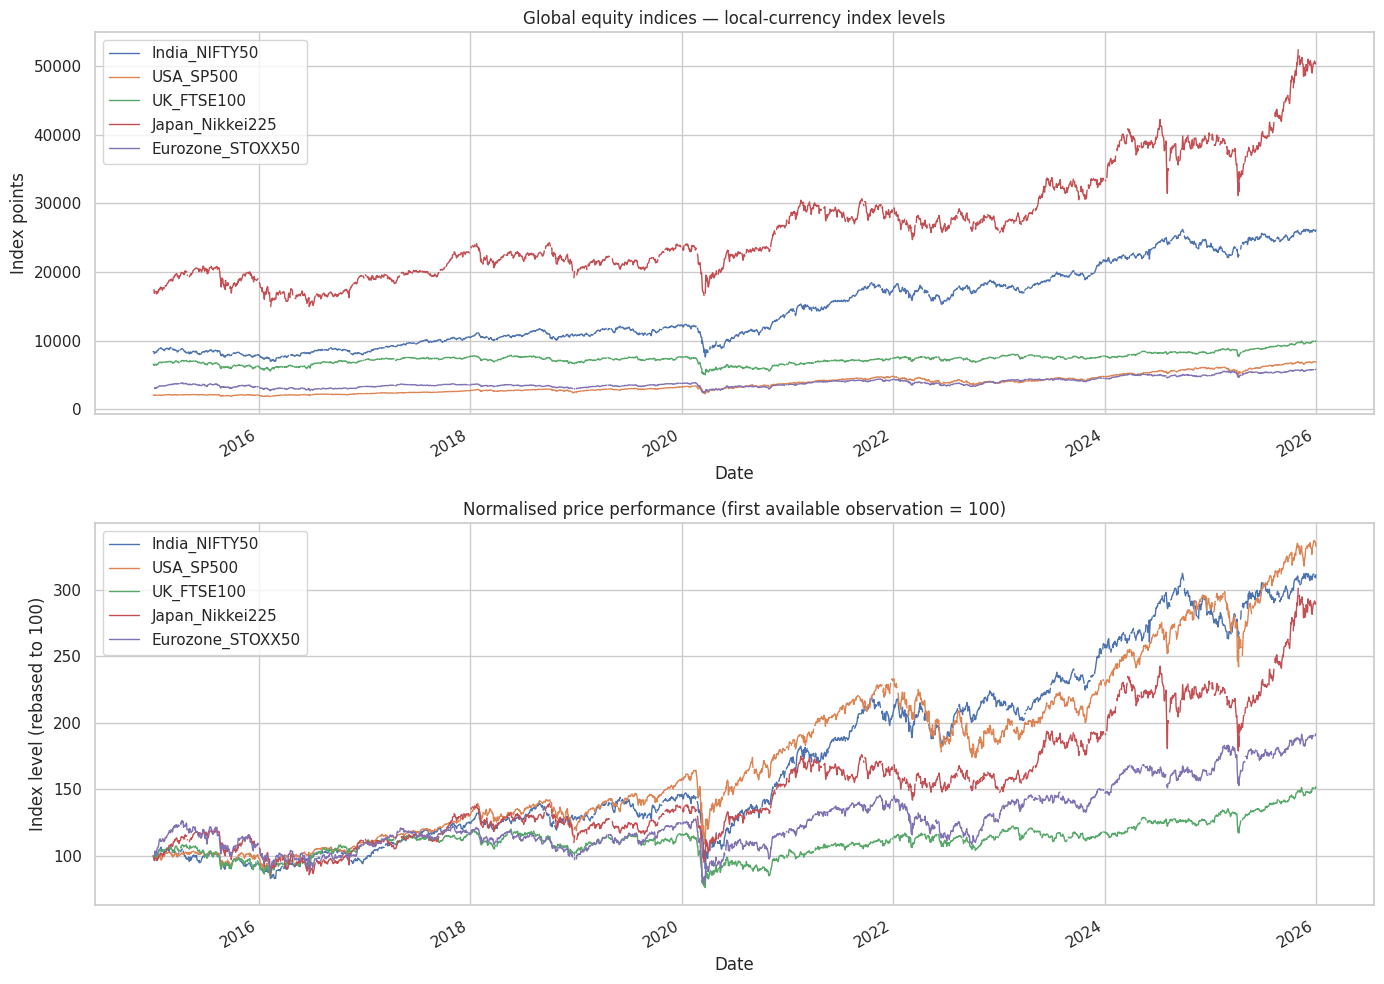

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(14, 10))
prices.plot(ax=axes[0], linewidth=1)
axes[0].set_title("Global equity indices — local-currency index levels")
axes[0].set_ylabel("Index points")

normalised = prices.div(prices.apply(lambda s: s.dropna().iloc[0]), axis=1) * 100
normalised.plot(ax=axes[1], linewidth=1)
axes[1].set_title("Normalised price performance (first available observation = 100)")
axes[1].set_ylabel("Index level (rebased to 100)")
plt.tight_layout()
plt.show()

## 4. Returns and descriptive risk statistics

,Annualised arithmetic return (%),Annualised volatility (%),Best daily return (%),Worst daily return (%),Observations
India_NIFTY50,14.8900,15.6300,6.6200,-8.3000,2027
USA_SP500,14.9200,18.3900,9.5200,-11.9800,2027
UK_FTSE100,5.0700,15.7800,9.0500,-10.8700,2027
Japan_Nikkei225,7.4900,20.8600,10.2300,-12.4000,2027
Eurozone_STOXX50,12.1300,19.3200,9.2400,-12.4000,2027


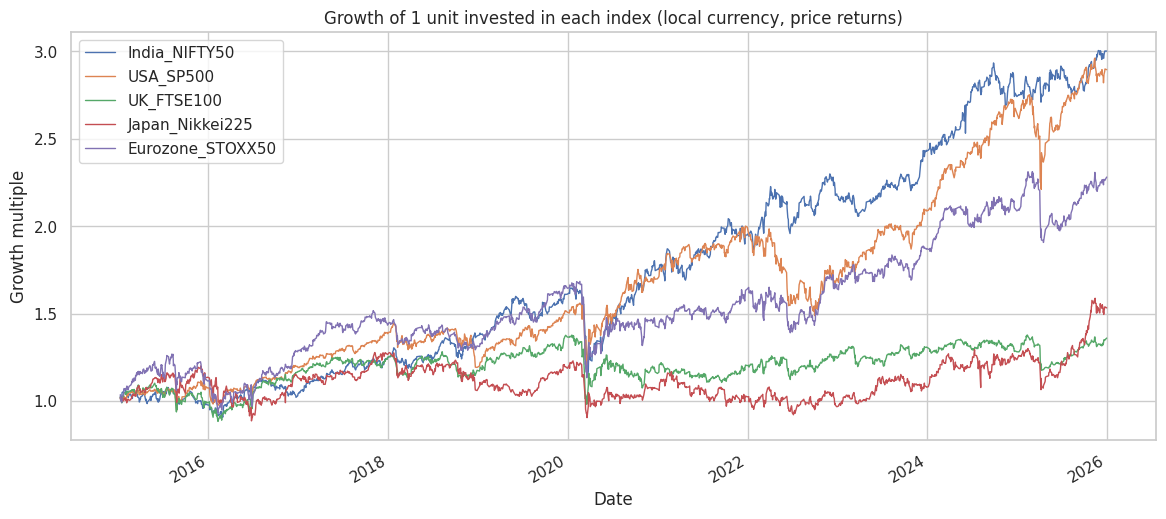

In [5]:
# Simple daily percentage returns; missing values remain missing.
returns = prices.pct_change(fill_method=None).dropna(how="all")
common_returns = returns.dropna(how="any")

TRADING_DAYS = 252
annualised_return = (1 + common_returns.mean()) ** TRADING_DAYS - 1
annualised_vol = common_returns.std() * np.sqrt(TRADING_DAYS)
daily_stats = pd.DataFrame({
    "Annualised arithmetic return (%)": common_returns.mean() * TRADING_DAYS * 100,
    "Annualised volatility (%)": annualised_vol * 100,
    "Best daily return (%)": common_returns.max() * 100,
    "Worst daily return (%)": common_returns.min() * 100,
    "Observations": common_returns.count()
})
display(daily_stats.round(2))

# Cumulative growth of 1 unit, using common dates for comparability.
growth = (1 + common_returns).cumprod()
ax = growth.plot(figsize=(14, 6), linewidth=1)
ax.set_title("Growth of 1 unit invested in each index (local currency, price returns)")
ax.set_ylabel("Growth multiple")
plt.show()

## 5. Market interdependence: correlation and rolling correlation

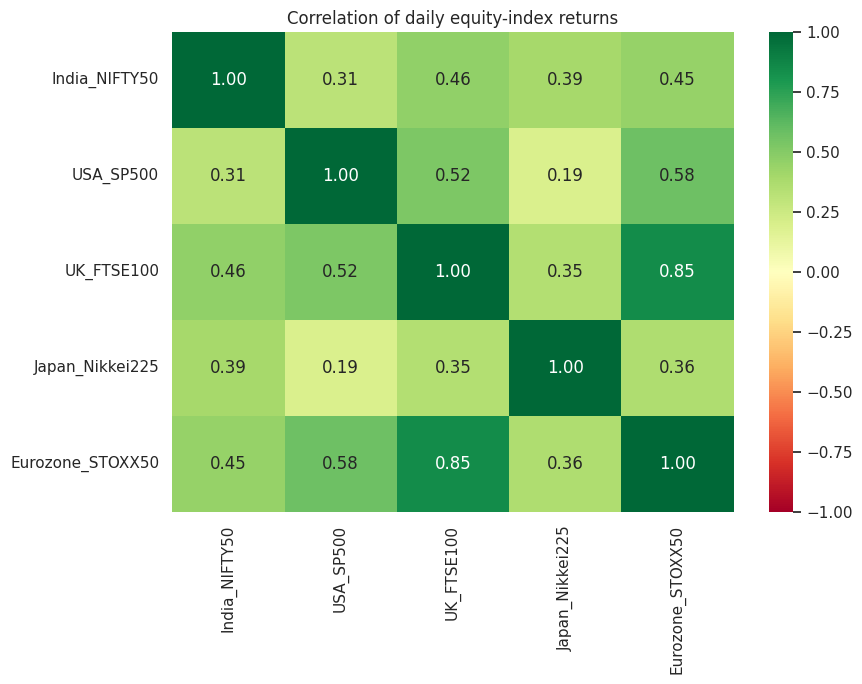

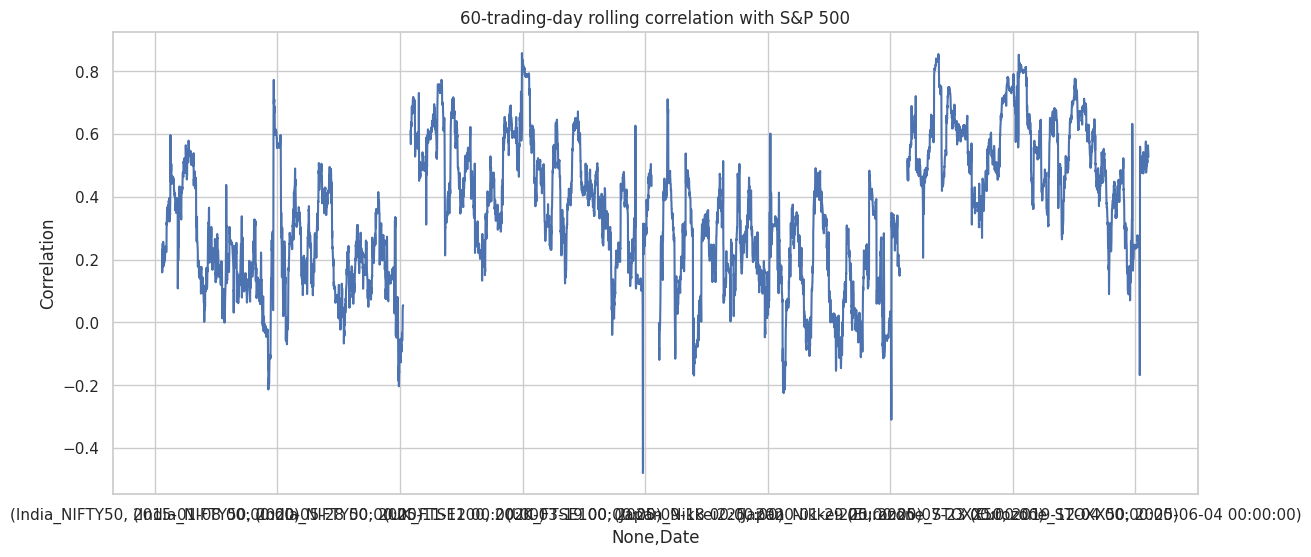

,India_NIFTY50,USA_SP500,UK_FTSE100,Japan_Nikkei225,Eurozone_STOXX50
India_NIFTY50,1.0000,0.3140,0.4610,0.3910,0.4530
USA_SP500,0.3140,1.0000,0.5240,0.1950,0.5750
UK_FTSE100,0.4610,0.5240,1.0000,0.3500,0.8460
Japan_Nikkei225,0.3910,0.1950,0.3500,1.0000,0.3630
Eurozone_STOXX50,0.4530,0.5750,0.8460,0.3630,1.0000


In [6]:
corr = common_returns.corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, cmap="RdYlGn", center=0, vmin=-1, vmax=1, fmt=".2f")
plt.title("Correlation of daily equity-index returns")
plt.tight_layout()
plt.show()

# 60-observation rolling pairwise correlations against the S&P 500
benchmark = "USA_SP500"
rolling_corr = common_returns.drop(columns=[benchmark]).rolling(60).corr(common_returns[benchmark])
rolling_corr.unstack().plot(figsize=(14, 6), title="60-trading-day rolling correlation with S&P 500")
plt.ylabel("Correlation")
plt.show()

display(corr.round(3))

**Interpretation guide:** correlation measures co-movement, not causation. Rolling correlations help show whether diversification benefits weaken during particular periods. The 60-observation window is a modelling choice, not a universal standard.

## 6. Time-series diagnostics: ADF stationarity tests

In [7]:
def adf_summary(series, label):
    x = series.dropna()
    result = adfuller(x, autolag="AIC")
    return {
        "Series": label,
        "ADF statistic": result[0],
        "p-value": result[1],
        "Used lags": result[2],
        "Observations": result[3],
        "5% critical value": result[4]["5%"],
        "Stationary at 5%": result[1] < 0.05
    }

price_adf = pd.DataFrame([adf_summary(prices[c], c) for c in prices.columns])
return_adf = pd.DataFrame([adf_summary(common_returns[c], c) for c in common_returns.columns])

print("ADF tests on price levels")
display(price_adf.round(4))
print("ADF tests on daily returns")
display(return_adf.round(4))

ADF tests on price levels


,Series,ADF statistic,p-value,Used lags,Observations,5% critical value,Stationary at 5%
0,India_NIFTY50,0.5271,0.9857,0,2707,-2.8626,False
1,USA_SP500,0.8112,0.9918,9,2756,-2.8626,False
2,UK_FTSE100,-0.5144,0.8892,24,2753,-2.8626,False
3,Japan_Nikkei225,0.6740,0.9893,3,2684,-2.8626,False
4,Eurozone_STOXX50,-0.6285,0.8644,0,2762,-2.8626,False


ADF tests on daily returns


,Series,ADF statistic,p-value,Used lags,Observations,5% critical value,Stationary at 5%
0,India_NIFTY50,-23.7140,0.0000,3,2023,-2.8630,True
1,USA_SP500,-12.4913,0.0000,15,2011,-2.8630,True
2,UK_FTSE100,-13.3891,0.0000,11,2015,-2.8630,True
3,Japan_Nikkei225,-18.4268,0.0000,7,2019,-2.8630,True
4,Eurozone_STOXX50,-20.0982,0.0000,5,2021,-2.8630,True


The Augmented Dickey–Fuller (ADF) test has a unit-root null hypothesis. A p-value below 0.05 is evidence against a unit root under the chosen specification. Equity price levels are often non-stationary, while returns are often stationary; results must be interpreted rather than assumed.

## 7. Johansen cointegration test

In [8]:
# Apply Johansen to log price levels on common dates.
log_prices = np.log(prices).dropna(how="any")
joh = coint_johansen(log_prices, det_order=0, k_ar_diff=1)

johansen_table = pd.DataFrame({
    "Rank hypothesis": ["r = 0", "r <= 1", "r <= 2", "r <= 3", "r <= 4"],
    "Trace statistic": joh.lr1,
    "5% critical value": joh.cvt[:, 1],
    "Reject at 5%": joh.lr1 > joh.cvt[:, 1]
})
display(johansen_table.round(3))

,Rank hypothesis,Trace statistic,5% critical value,Reject at 5%
0,r = 0,51.5990,69.8190,False
1,r <= 1,28.1680,47.8540,False
2,r <= 2,13.4620,29.7960,False
3,r <= 3,6.3170,15.4940,False
4,r <= 4,0.0290,3.8420,False


**Interpretation:** Johansen tests whether a set of non-stationary price series share one or more cointegrating relationships. This is sensitive to deterministic terms and lag selection. Treat this as an exploratory specification; do not claim a stable long-run relationship without robustness checks.

## 8. Portfolio risk: VaR, Expected Shortfall and drawdown

,Confidence,Daily VaR (loss %),Daily Expected Shortfall (loss %)
0,95%,1.2040,2.0800
1,99%,2.4070,4.0070


Maximum drawdown: -27.34%
Maximum drawdown trough date: 2020-03-18


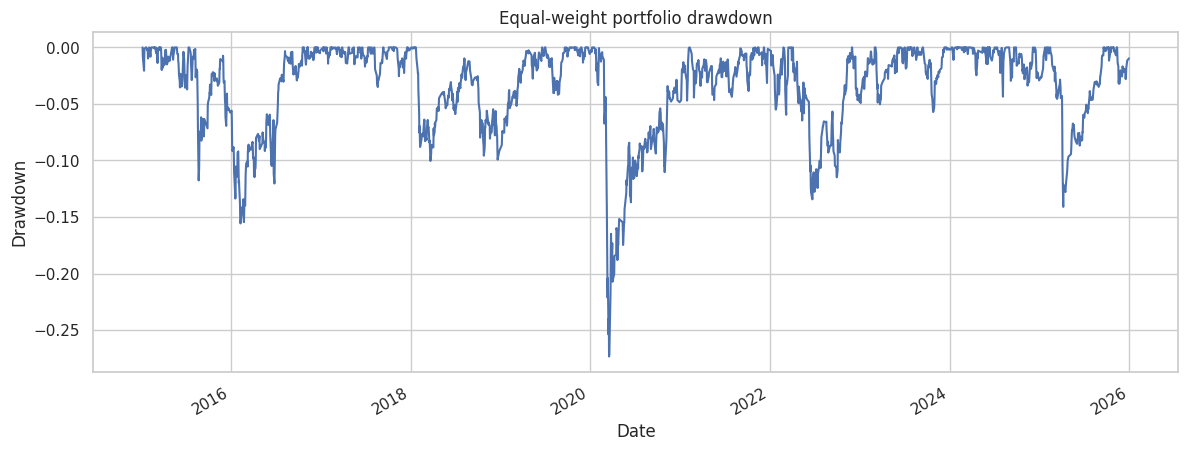

In [9]:
# Equal-weight portfolio, rebalanced daily on common observation dates.
weights = np.repeat(1 / len(common_returns.columns), len(common_returns.columns))
portfolio_returns = common_returns @ weights

def historical_var_es(x, confidence=0.95):
    q = np.quantile(x, 1 - confidence)
    tail = x[x <= q]
    return q, tail.mean()

risk_rows = []
for conf in [0.95, 0.99]:
    var, es = historical_var_es(portfolio_returns, conf)
    risk_rows.append({
        "Confidence": f"{int(conf*100)}%",
        "Daily VaR (loss %)": -var * 100,
        "Daily Expected Shortfall (loss %)": -es * 100
    })
risk_table = pd.DataFrame(risk_rows)
display(risk_table.round(3))

wealth = (1 + portfolio_returns).cumprod()
running_peak = wealth.cummax()
drawdown = wealth / running_peak - 1
max_drawdown = drawdown.min()
max_dd_date = drawdown.idxmin()

print(f"Maximum drawdown: {max_drawdown:.2%}")
print(f"Maximum drawdown trough date: {max_dd_date.date()}")

fig, ax = plt.subplots(figsize=(14, 5))
drawdown.plot(ax=ax)
ax.set_title("Equal-weight portfolio drawdown")
ax.set_ylabel("Drawdown")
plt.show()

VaR is the historical loss threshold at the selected confidence level. Expected Shortfall is the average loss conditional on breaching that threshold. Both are historical estimates and depend on the sample window; they do not guarantee a maximum loss.

## 9. Historical stress episode: COVID-19 market shock

In [10]:
# Predefined broad market stress window; report actual sample outcomes.
covid_start, covid_end = "2020-02-19", "2020-03-23"
covid_returns = common_returns.loc[covid_start:covid_end]

if covid_returns.empty:
    print("COVID window unavailable in the downloaded common-date sample.")
else:
    covid_cumulative = (1 + covid_returns).prod() - 1
    covid_table = pd.DataFrame({
        "Cumulative return during stress window (%)": covid_cumulative * 100
    }).sort_values("Cumulative return during stress window (%)")
    display(covid_table.round(2))

    covid_portfolio = (1 + portfolio_returns.loc[covid_start:covid_end]).prod() - 1
    print(f"Equal-weight portfolio cumulative return: {covid_portfolio:.2%}")

,Cumulative return during stress window (%)
Eurozone_STOXX50,-30.2900
India_NIFTY50,-29.4900
UK_FTSE100,-24.9300
Japan_Nikkei225,-24.7900
USA_SP500,-22.7700


Equal-weight portfolio cumulative return: -26.23%


## 10. Hypothetical equity shock scenarios

In [11]:
# Explicit, illustrative shocks to each local-currency equity index.
# These are assumptions for sensitivity analysis, not forecasts or regulatory scenarios.
scenarios = pd.DataFrame({
    "Scenario": [
        "Broad global sell-off",
        "US-led correction",
        "Asia-led sell-off",
        "Europe-led sell-off"
    ],
    "India_NIFTY50": [-0.20, -0.10, -0.25, -0.10],
    "USA_SP500": [-0.20, -0.30, -0.15, -0.10],
    "UK_FTSE100": [-0.20, -0.12, -0.15, -0.25],
    "Japan_Nikkei225": [-0.20, -0.12, -0.30, -0.12],
    "Eurozone_STOXX50": [-0.20, -0.12, -0.15, -0.30],
}).set_index("Scenario")

scenario_weights = pd.Series(1 / len(common_returns.columns), index=common_returns.columns)
scenario_results = scenarios.mul(scenario_weights, axis=1).sum(axis=1) * 100
scenario_results = scenario_results.rename("Equal-weight portfolio shock (%)").to_frame()
display(scenarios.mul(100).round(1))
display(scenario_results.round(2))

,India_NIFTY50,USA_SP500,UK_FTSE100,Japan_Nikkei225,Eurozone_STOXX50
Scenario,,,,,
Broad global sell-off,-20.0000,-20.0000,-20.0000,-20.0000,-20.0000
US-led correction,-10.0000,-30.0000,-12.0000,-12.0000,-12.0000
Asia-led sell-off,-25.0000,-15.0000,-15.0000,-30.0000,-15.0000
Europe-led sell-off,-10.0000,-10.0000,-25.0000,-12.0000,-30.0000


,Equal-weight portfolio shock (%)
Scenario,
Broad global sell-off,-20.0000
US-led correction,-15.2000
Asia-led sell-off,-20.0000
Europe-led sell-off,-17.4000


**Scenario design:** shocks are transparent deterministic assumptions. Equal weights are used to make the calculation easy to explain. A real risk exercise would justify shocks using market history, macro-financial linkages, risk appetite, portfolio exposures and governance review.

## 11. Worst rolling 10-day portfolio periods

In [12]:
rolling_10d = (1 + portfolio_returns).rolling(10).apply(np.prod, raw=True) - 1
worst_10d = rolling_10d.nsmallest(5).rename("10-day cumulative return (%)") * 100
display(worst_10d.to_frame().round(2))

,10-day cumulative return (%)
Date,
2020-03-18,-23.0700
2020-03-19,-22.7900
2020-03-16,-22.4200
2020-03-12,-21.5300
2020-03-13,-19.5200


## 12. Exporting outputs for the project repository

In [13]:
# Export source data, returns, core tables and scenario outputs.
prices.to_csv("global_equity_index_prices_2015_2025.csv")
common_returns.to_csv("global_equity_daily_returns_2015_2025.csv")
corr.to_csv("daily_return_correlation_matrix.csv")
daily_stats.to_csv("market_risk_summary.csv")
risk_table.to_csv("portfolio_var_es.csv", index=False)
scenario_results.to_csv("hypothetical_scenario_results.csv")
johansen_table.to_csv("johansen_cointegration_results.csv", index=False)

print("Exports created successfully.")

Exports created successfully.


In [14]:
import zipfile
from google.colab import files

output_files = [
    "global_equity_index_prices_2015_2025.csv",
    "global_equity_daily_returns_2015_2025.csv",
    "daily_return_correlation_matrix.csv",
    "market_risk_summary.csv",
    "portfolio_var_es.csv",
    "hypothetical_scenario_results.csv",
    "johansen_cointegration_results.csv"
]

with zipfile.ZipFile("Global_Equity_Analysis_Results.zip", "w") as z:
    for file in output_files:
        z.write(file)

files.download("Global_Equity_Analysis_Results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>